<a href="https://colab.research.google.com/github/ZiyuCao421/CP5408-TR3-Cyber-Security-Strategy/blob/main/02-weekly-practicals/week-06/Example_Practical_6_Completed.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CP5408 Practical 6: Normalising Security Tool Data (completed example)

This notebook is a small, hands-on version of the Week 6 case study, in which a security assessment team had to combine vulnerability data from several tools before they could compare two business units.

The dataset is **synthetic**. It contains the same kinds of problem the team met: inconsistent labels, *pseudo-services* in the port field, several vulnerability IDs packed into one field, vulnerabilities with no CVSS score, and a text file whose fields contain commas.

You do not need to write code. Run the cells from top to bottom. The only cell you change is the **decision settings** cell in Section 3. Figures are saved as PNG files beside the notebook.

## 0. Setup

In [1]:
import csv, io, re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option('display.max_colwidth', 60)
pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', '{:,.2f}'.format)

SAVE_FIGURES = True
def finish(fig_name):
    plt.tight_layout()
    if SAVE_FIGURES:
        plt.savefig(f'{fig_name}.png', dpi=200, bbox_inches='tight')
    plt.show()

## 1. The raw data

Three tables, as they might arrive from different tools:

- `raw_findings`: one row per finding, from three scanners.
- `cvss_lookup`: CVSS scores by vulnerability ID. Some vulnerabilities are unscored, and some IDs are not in the table at all.
- `asset_criticality`: what each asset is and how much it matters to the business.

In [2]:
raw_findings = pd.DataFrame({
    'asset_id': ['A-001','A-002','A-003','A-004','A-005','A-006','A-007','A-008','A-009','A-010','A-011','A-012'],
    'business_unit': ['Warehouse Ops','Warehouse Ops','Wearables','Wearables','Drone Ops','Drone Ops','Warehouse Ops','Drone Ops','Wearables','Warehouse Ops','Drone Ops','Wearables'],
    'ip_address': ['10.1.1.10','10.1.1.25','10.2.5.40','10.2.5.41','10.3.8.10','10.3.8.11','10.1.1.80','10.3.8.20','10.2.5.90','10.1.1.90','10.3.8.50','10.2.5.91'],
    'port': ['443TCP','22TCP','Windows','8080TCP','TCP/IP','161UDP','443TCP','GPS-Service','80TCP','445TCP','443TCP','Bluetooth'],
    'vulnerability_id': ['VID-101','VID-102;VID-205','VID-103','VID-104','VID-105','VID-106','VID-207','VID-108;VID-109','VID-110','VID-111','VID-112','VID-113'],
    'vulnerability_name': [
        'Outdated TLS configuration', 'Weak SSH cipher; default admin account', 'Anonymous NetBIOS enumeration',
        'Exposed application admin panel', 'Predictable TCP sequence numbers', 'Weak SNMP community string',
        'Expired certificate', 'GPS command API exposed; missing auth', 'Unpatched web server',
        'SMB signing not required', 'Cloud API key exposed', 'Insecure Bluetooth pairing'],
    'severity': ['High','medium','HIGH','Critical','high','Medium','Low','critical','High','medium','Critical','HIGH'],
    'status': ['confirmed','potential','confirmed','confirmed','potential','confirmed','potential','confirmed','confirmed','potential','confirmed','confirmed'],
    'source_tool': ['ScannerA','ScannerB','ScannerB','ScannerA','ScannerC','ScannerA','ScannerB','ScannerC','ScannerA','ScannerB','ScannerC','ScannerB'],
})

cvss_lookup = pd.DataFrame({
    'vulnerability_id': ['VID-101','VID-102','VID-103','VID-104','VID-105','VID-106','VID-108','VID-109','VID-110','VID-111','VID-112','VID-113'],
    'cvss_base': [7.4, 6.5, np.nan, 9.1, np.nan, 6.8, 8.8, 7.9, 8.1, 6.2, 9.5, np.nan],
    'cvss_source': ['NVD','NVD','Unscored','NVD','Unscored','NVD','NVD','NVD','NVD','NVD','NVD','Unscored'],
})

asset_criticality = pd.DataFrame({
    'asset_id': ['A-001','A-002','A-003','A-004','A-005','A-006','A-007','A-008','A-009','A-010','A-011','A-012'],
    'asset_role': ['Web API','Admin Server','Legacy Windows Host','Customer App Server','Drone Control Stack','Network Device','Web API','Drone API','Web Server','File Server','Cloud Integration','Wearable Gateway'],
    'criticality': ['High','High','Medium','High','Critical','Medium','Medium','Critical','High','Medium','Critical','High'],
})

raw_findings

,asset_id,business_unit,ip_address,port,vulnerability_id,vulnerability_name,severity,status,source_tool
0,A-001,Warehouse Ops,10.1.1.10,443TCP,VID-101,Outdated TLS configuration,High,confirmed,ScannerA
1,A-002,Warehouse Ops,10.1.1.25,22TCP,VID-102;VID-205,Weak SSH cipher; default admin account,medium,potential,ScannerB
2,A-003,Wearables,10.2.5.40,Windows,VID-103,Anonymous NetBIOS enumeration,HIGH,confirmed,ScannerB
3,A-004,Wearables,10.2.5.41,8080TCP,VID-104,Exposed application admin panel,Critical,confirmed,ScannerA
4,A-005,Drone Ops,10.3.8.10,TCP/IP,VID-105,Predictable TCP sequence numbers,high,potential,ScannerC
5,A-006,Drone Ops,10.3.8.11,161UDP,VID-106,Weak SNMP community string,Medium,confirmed,ScannerA
6,A-007,Warehouse Ops,10.1.1.80,443TCP,VID-207,Expired certificate,Low,potential,ScannerB
7,A-008,Drone Ops,10.3.8.20,GPS-Service,VID-108;VID-109,GPS command API exposed; missing auth,critical,confirmed,ScannerC
8,A-009,Wearables,10.2.5.90,80TCP,VID-110,Unpatched web server,High,confirmed,ScannerA
9,A-010,Warehouse Ops,10.1.1.90,445TCP,VID-111,SMB signing not required,medium,potential,ScannerB


## 2. Inspect before you clean

Look for: severity labels written different ways; values in `port` that are not ports; rows with more than one vulnerability ID; and IDs that will not find a CVSS score.

In [3]:
print('Severity labels as recorded:')
print(raw_findings['severity'].value_counts().to_string())

is_port = raw_findings['port'].str.match(r'^\d{1,5}(TCP|UDP)$')
print('\nValues in the port field that are not a port number and protocol (pseudo-services):')
print(raw_findings.loc[~is_port, ['asset_id', 'port', 'vulnerability_name']].to_string(index=False))

print('\nRows with more than one vulnerability ID in the field:')
print(raw_findings.loc[raw_findings['vulnerability_id'].str.contains(';'), ['asset_id', 'vulnerability_id']].to_string(index=False))

all_ids = raw_findings['vulnerability_id'].str.split(';').explode().str.strip()
print('\nVulnerability IDs with no entry in the CVSS lookup table:', sorted(set(all_ids) - set(cvss_lookup['vulnerability_id'])))
print('Vulnerability IDs listed in the lookup but unscored:', cvss_lookup.loc[cvss_lookup['cvss_base'].isna(), 'vulnerability_id'].tolist())

Severity labels as recorded:
severity
High        2
medium      2
HIGH        2
Critical    2
high        1
Medium      1
Low         1
critical    1

Values in the port field that are not a port number and protocol (pseudo-services):
asset_id        port                    vulnerability_name
   A-003     Windows         Anonymous NetBIOS enumeration
   A-005      TCP/IP      Predictable TCP sequence numbers
   A-008 GPS-Service GPS command API exposed; missing auth
   A-012   Bluetooth            Insecure Bluetooth pairing

Rows with more than one vulnerability ID in the field:
asset_id vulnerability_id
   A-002  VID-102;VID-205
   A-008  VID-108;VID-109

Vulnerability IDs with no entry in the CVSS lookup table: ['VID-205', 'VID-207']
Vulnerability IDs listed in the lookup but unscored: ['VID-103', 'VID-105', 'VID-113']


## 3. Decision settings, then clean and normalise

Standardising `HIGH`, `high` and `High` needs no judgement. Three other steps do, and each is a decision the case-study team actually faced. Set your choices, run the rest of the notebook, record the results in your worksheet, then change **one** setting and run again.

| Setting | Options | The decision |
|---|---|---|
| `SPLIT_MULTI_IDS` | `True` or `False` | Split rows that contain several vulnerability IDs into one row per ID? With `False`, only the first ID in the field is matched and the rest are ignored, which is what happened to the case-study team's first database query. |
| `PSEUDO_SERVICE_RULE` | `'keep'` or `'remove'` | Keep findings whose port field holds a pseudo-service (such as `Windows` or `TCP/IP`), or remove them because they are not standard ports? |
| `UNSCORED_RULE` | `'estimate'` or `'exclude'` | For vulnerabilities with no CVSS score, assign a documented estimate based on the severity label, or leave them out? |

In [4]:
# ---- DECISION SETTINGS: this is the only cell you need to edit ----
SPLIT_MULTI_IDS = True             # True or False
PSEUDO_SERVICE_RULE = 'keep'       # 'keep' or 'remove'
UNSCORED_RULE = 'estimate'         # 'estimate' or 'exclude'

In [5]:
if SPLIT_MULTI_IDS not in (True, False):
    raise ValueError("SPLIT_MULTI_IDS must be True or False (no quotes).")
if PSEUDO_SERVICE_RULE not in ('keep', 'remove'):
    raise ValueError("PSEUDO_SERVICE_RULE must be 'keep' or 'remove'. Check the spelling and the quotes.")
if UNSCORED_RULE not in ('estimate', 'exclude'):
    raise ValueError("UNSCORED_RULE must be 'estimate' or 'exclude'. Check the spelling and the quotes.")

SEVERITY_TO_CVSS = {'Low': 3.0, 'Medium': 5.5, 'High': 7.5, 'Critical': 9.0}   # documented rule for estimates

def normalise(split_ids, pseudo_rule, unscored_rule):
    log = []
    d = raw_findings.copy()

    # Step 1. Standardise labels (no judgement needed)
    d['severity'] = d['severity'].str.strip().str.title()
    d['status'] = d['status'].str.strip().str.title()
    log.append(f"Severity: {raw_findings['severity'].nunique()} different labels standardised to {d['severity'].nunique()}.")

    # Step 2. Separate standard ports from pseudo-services
    parts = d['port'].str.extract(r'^(\d{1,5})(TCP|UDP)$')
    d['port_number'] = pd.to_numeric(parts[0], errors='coerce')
    d['protocol'] = parts[1]
    d['is_pseudo_service'] = d['port_number'].isna()
    n_pseudo = int(d['is_pseudo_service'].sum())
    if pseudo_rule == 'remove':
        d = d[~d['is_pseudo_service']].copy()
        log.append(f"Pseudo-services: {n_pseudo} findings REMOVED because the port field was not a standard port.")
    else:
        log.append(f"Pseudo-services: {n_pseudo} findings kept and flagged (is_pseudo_service = True).")

    # Step 3. Several vulnerability IDs in one field
    n_multi = int(d['vulnerability_id'].str.contains(';').sum())
    if split_ids:
        d['vulnerability_id'] = d['vulnerability_id'].str.split(';')
        d = d.explode('vulnerability_id')
        d['vulnerability_id'] = d['vulnerability_id'].str.strip()
        log.append(f"Multiple IDs: {n_multi} rows split into one row per vulnerability ID.")
    else:
        ignored = d.loc[d['vulnerability_id'].str.contains(';'), 'vulnerability_id'].str.split(';').str[1:].explode().str.strip().tolist()
        d['vulnerability_id'] = d['vulnerability_id'].str.split(';').str[0].str.strip()
        log.append(f"Multiple IDs: NOT split. Only the first ID in each field was used; these were silently ignored: {ignored}.")

    # Step 4. Merge CVSS scores and asset information
    d = d.merge(cvss_lookup, on='vulnerability_id', how='left').merge(asset_criticality, on='asset_id', how='left')
    d['cvss_source'] = d['cvss_source'].fillna('Not in lookup')

    # Step 5. Vulnerabilities with no CVSS score
    d['cvss_was_estimated'] = d['cvss_base'].isna()
    n_unscored = int(d['cvss_was_estimated'].sum())
    if unscored_rule == 'estimate':
        d['cvss'] = d['cvss_base'].fillna(d['severity'].map(SEVERITY_TO_CVSS))
        log.append(f"Unscored: {n_unscored} findings had no CVSS score and were given a documented estimate from their severity label {SEVERITY_TO_CVSS}.")
    else:
        d = d[~d['cvss_was_estimated']].copy()
        d['cvss'] = d['cvss_base']
        log.append(f"Unscored: {n_unscored} findings had no CVSS score and were EXCLUDED from the analysis.")

    # Step 6. A simple, documented priority score (for demonstration only)
    d['priority_score'] = (d['cvss']
                           * d['criticality'].map({'Low': 0.8, 'Medium': 1.0, 'High': 1.2, 'Critical': 1.5})
                           * d['status'].map({'Potential': 0.8, 'Confirmed': 1.2}))
    return d.reset_index(drop=True), log

normalised, cleaning_log = normalise(SPLIT_MULTI_IDS, PSEUDO_SERVICE_RULE, UNSCORED_RULE)

print('CLEANING LOG')
for i, entry in enumerate(cleaning_log, 1):
    print(f'{i}. {entry}')
print(f'\nFindings in the raw data: {len(raw_findings)} rows.  Findings in the analysis: {len(normalised)}.')
normalised[['asset_id', 'business_unit', 'vulnerability_id', 'severity', 'status', 'is_pseudo_service', 'cvss_base', 'cvss', 'cvss_was_estimated', 'criticality']]

CLEANING LOG
1. Severity: 8 different labels standardised to 4.
2. Pseudo-services: 4 findings kept and flagged (is_pseudo_service = True).
3. Multiple IDs: 2 rows split into one row per vulnerability ID.
4. Unscored: 5 findings had no CVSS score and were given a documented estimate from their severity label {'Low': 3.0, 'Medium': 5.5, 'High': 7.5, 'Critical': 9.0}.

Findings in the raw data: 12 rows.  Findings in the analysis: 14.


,asset_id,business_unit,vulnerability_id,severity,status,is_pseudo_service,cvss_base,cvss,cvss_was_estimated,criticality
0,A-001,Warehouse Ops,VID-101,High,Confirmed,False,7.40,7.40,False,High
1,A-002,Warehouse Ops,VID-102,Medium,Potential,False,6.50,6.50,False,High
2,A-002,Warehouse Ops,VID-205,Medium,Potential,False,NaN,5.50,True,High
3,A-003,Wearables,VID-103,High,Confirmed,True,NaN,7.50,True,Medium
4,A-004,Wearables,VID-104,Critical,Confirmed,False,9.10,9.10,False,High
5,A-005,Drone Ops,VID-105,High,Potential,True,NaN,7.50,True,Critical
6,A-006,Drone Ops,VID-106,Medium,Confirmed,False,6.80,6.80,False,Medium
7,A-007,Warehouse Ops,VID-207,Low,Potential,False,NaN,3.00,True,Medium
8,A-008,Drone Ops,VID-108,Critical,Confirmed,True,8.80,8.80,False,Critical
9,A-008,Drone Ops,VID-109,Critical,Confirmed,True,7.90,7.90,False,Critical


## 4. A file-format problem: commas inside a field

The case-study team exported findings as CSV (comma-separated) files and loaded them into a database. Some vulnerability names contained commas, so a naive split on commas cut the name short. Their quick fix was a search-and-replace that deleted any comma following a letter. Run the cell and look closely at what that fix did to the data.

In [6]:
csv_text = '"1.1.1.1","windows","ISAPI, Extension for Windows Media Service Buffer Overflow"\n' \
           '"2.2.2.2","windows","iisadmin Directory Present Vulnerability"\n'

print('1. Naive split on every comma (what the first import effectively did):')
for line in csv_text.strip().split('\n'):
    fields = line.split(',')
    print(f'   {len(fields)} fields -> vulnerability = {fields[2]}')

print('\n2. The quick fix from the case study: delete a letter-plus-comma wherever it occurs  (s/[a-zA-Z],//g)')
fixed = re.sub(r'[a-zA-Z],', '', csv_text)
for line in fixed.strip().split('\n'):
    print('  ', line)

print('\n3. A CSV-aware reader that respects the quotation marks:')
for row in csv.reader(io.StringIO(csv_text)):
    print(f'   {len(row)} fields -> vulnerability = {row[2]}')

1. Naive split on every comma (what the first import effectively did):
   4 fields -> vulnerability = "ISAPI
   3 fields -> vulnerability = "iisadmin Directory Present Vulnerability"

2. The quick fix from the case study: delete a letter-plus-comma wherever it occurs  (s/[a-zA-Z],//g)
   "1.1.1.1","windows","ISAP Extension for Windows Media Service Buffer Overflow"
   "2.2.2.2","windows","iisadmin Directory Present Vulnerability"

3. A CSV-aware reader that respects the quotation marks:
   3 fields -> vulnerability = ISAPI, Extension for Windows Media Service Buffer Overflow
   3 fields -> vulnerability = iisadmin Directory Present Vulnerability


## 5. Analyse the normalised data

The customer in the case study wanted to compare business units. These outputs do that. Each chart title records the settings that produced it.

In [7]:
settings_label = f"split IDs: {SPLIT_MULTI_IDS}; pseudo-services: {PSEUDO_SERVICE_RULE}; unscored: {UNSCORED_RULE}"
severity_order = ['Low', 'Medium', 'High', 'Critical']

summary = normalised.groupby('business_unit').agg(
    Findings=('vulnerability_id', 'count'),
    Confirmed=('status', lambda s: int((s == 'Confirmed').sum())),
    High_or_critical=('severity', lambda s: int(s.isin(['High', 'Critical']).sum())),
    Estimated_scores=('cvss_was_estimated', 'sum'),
    Mean_CVSS=('cvss', 'mean'),
    Median_CVSS=('cvss', 'median'),
)
summary

,Findings,Confirmed,High_or_critical,Estimated_scores,Mean_CVSS,Median_CVSS
business_unit,,,,,,
Drone Ops,5,4,4,1,8.10,7.90
Warehouse Ops,5,1,1,2,5.72,6.20
Wearables,4,4,4,2,8.05,7.80


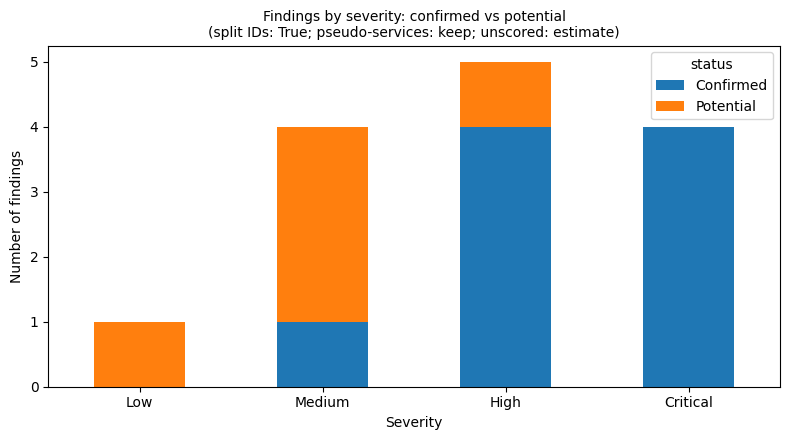

In [8]:
status_by_severity = (normalised.groupby(['severity', 'status']).size().unstack(fill_value=0)
                      .reindex(severity_order, fill_value=0))
for col in ['Confirmed', 'Potential']:
    if col not in status_by_severity.columns:
        status_by_severity[col] = 0

ax = status_by_severity[['Confirmed', 'Potential']].plot(kind='bar', stacked=True, figsize=(8, 4.5))
ax.set_xlabel('Severity')
ax.set_ylabel('Number of findings')
ax.set_title(f'Findings by severity: confirmed vs potential\n({settings_label})', fontsize=10)
plt.xticks(rotation=0)
finish('p6_fig1_severity_confirmed_vs_potential')

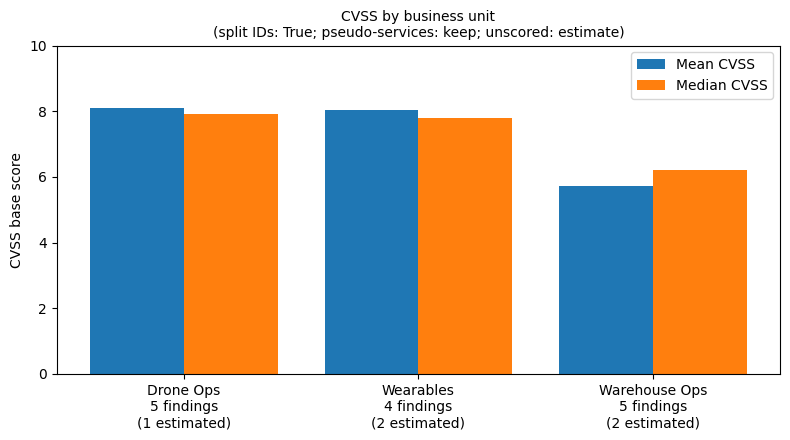

In [9]:
bu = summary.sort_values('Mean_CVSS', ascending=False)
x = np.arange(len(bu))
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(x - 0.2, bu['Mean_CVSS'], width=0.4, label='Mean CVSS')
ax.bar(x + 0.2, bu['Median_CVSS'], width=0.4, label='Median CVSS')
ax.set_xticks(x)
ax.set_xticklabels([f'{name}\n{n} findings\n({int(est)} estimated)'
                    for name, n, est in zip(bu.index, bu['Findings'], bu['Estimated_scores'])])
ax.set_ylim(0, 10)
ax.set_ylabel('CVSS base score')
ax.set_title(f'CVSS by business unit\n({settings_label})', fontsize=10)
ax.legend()
finish('p6_fig2_cvss_by_business_unit')

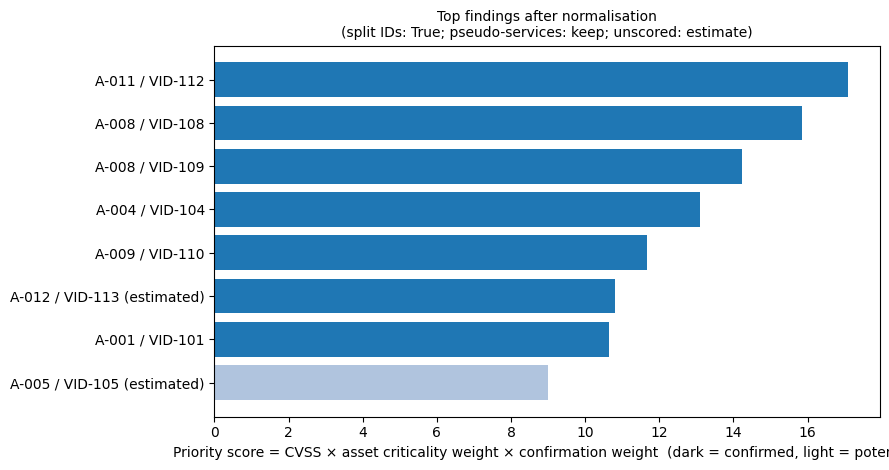

In [10]:
top = normalised.sort_values('priority_score', ascending=False).head(8).sort_values('priority_score')
labels = top['asset_id'] + ' / ' + top['vulnerability_id'] + np.where(top['cvss_was_estimated'], ' (estimated)', '')
colours = np.where(top['status'] == 'Confirmed', 'tab:blue', 'lightsteelblue')

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh(labels, top['priority_score'], color=colours)
ax.set_xlabel('Priority score = CVSS × asset criticality weight × confirmation weight  (dark = confirmed, light = potential)')
ax.set_title(f'Top findings after normalisation\n({settings_label})', fontsize=10)
finish('p6_fig3_top_findings')

## 6. Questions (answer in your worksheet)

1. With the default settings, how many findings are analysed, and why is that more than the number of raw rows?
2. Set `SPLIT_MULTI_IDS = False` and run again. Which vulnerabilities disappear? Was there an error message?
3. Set `PSEUDO_SERVICE_RULE = 'remove'`. Which business unit's picture changes most, and why is that dangerous?
4. Set `UNSCORED_RULE = 'exclude'`. What is lost?
5. Look at Figure 2. The Week 4 seminar treated CVSS as interval data, but many practitioners regard it as ordinal. Which bar would you trust more, mean or median, and why?
6. In Section 4, what did the quick fix do to the word *ISAPI*? What does that tell you about checking a cleaning step?

## Tutor reference: every combination of settings

Not in the student notebook.

In [11]:
rows = []
for split in (True, False):
    for pseudo in ('keep', 'remove'):
        for unscored in ('estimate', 'exclude'):
            d, _ = normalise(split, pseudo, unscored)
            means = d.groupby('business_unit')['cvss'].mean()
            rows.append({'SPLIT': split, 'PSEUDO': pseudo, 'UNSCORED': unscored, 'Findings': len(d),
                         'Drone Ops n': int((d['business_unit'] == 'Drone Ops').sum()),
                         'Drone Ops mean': means.get('Drone Ops', np.nan),
                         'Wearables mean': means.get('Wearables', np.nan),
                         'Warehouse Ops mean': means.get('Warehouse Ops', np.nan),
                         'Top finding': d.sort_values('priority_score', ascending=False).iloc[0][['asset_id', 'vulnerability_id']].str.cat(sep=' / ')})
pd.DataFrame(rows)

,SPLIT,PSEUDO,UNSCORED,Findings,Drone Ops n,Drone Ops mean,Wearables mean,Warehouse Ops mean,Top finding
0,True,keep,estimate,14,5,8.10,8.05,5.72,A-011 / VID-112
1,True,keep,exclude,9,4,8.25,8.60,6.70,A-011 / VID-112
2,True,remove,estimate,9,2,8.15,8.60,5.72,A-011 / VID-112
3,True,remove,exclude,7,2,8.15,8.60,6.70,A-011 / VID-112
4,False,keep,estimate,12,4,8.15,8.05,5.78,A-011 / VID-112
5,False,keep,exclude,8,3,8.37,8.60,6.70,A-011 / VID-112
6,False,remove,estimate,8,2,8.15,8.60,5.78,A-011 / VID-112
7,False,remove,exclude,7,2,8.15,8.60,6.70,A-011 / VID-112
